In [1]:
import pandas as pd

df = pd.read_csv("amazon.csv")

print("Shape:", df.shape)

df[['discounted_price',
    'discount_percentage',
    'rating',
    'rating_count']].head()

Shape: (1465, 16)


,discounted_price,discount_percentage,rating,rating_count
0,₹399,64%,4.2,"24,269"
1,₹199,43%,4.0,"43,994"
2,₹199,90%,3.9,"7,928"
3,₹329,53%,4.2,"94,363"
4,₹154,61%,4.2,"16,905"


In [2]:
df[['discounted_price',
    'discount_percentage',
    'rating',
    'rating_count']].info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   discounted_price     1465 non-null   str  
 1   discount_percentage  1465 non-null   str  
 2   rating               1465 non-null   str  
 3   rating_count         1463 non-null   str  
dtypes: str(4)
memory usage: 45.9 KB


In [3]:
df[['discounted_price',
    'discount_percentage',
    'rating',
    'rating_count']].isnull().sum()

discounted_price       0
discount_percentage    0
rating                 0
rating_count           2
dtype: int64

In [4]:
df['discounted_price'] = (
    df['discounted_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

df['discount_percentage'] = (
    df['discount_percentage']
    .str.replace('%', '', regex=False)
    .astype(float)
)

df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

df['rating_count'] = (
    df['rating_count']
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [5]:
df[['discounted_price',
    'discount_percentage',
    'rating',
    'rating_count']].info()

<class 'pandas.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   discounted_price     1465 non-null   float64
 1   discount_percentage  1465 non-null   float64
 2   rating               1464 non-null   float64
 3   rating_count         1463 non-null   float64
dtypes: float64(4)
memory usage: 45.9 KB


In [6]:
df[['discounted_price',
    'discount_percentage',
    'rating',
    'rating_count']].isnull().sum()

discounted_price       0
discount_percentage    0
rating                 1
rating_count           2
dtype: int64

In [7]:
df[df[['rating', 'rating_count']].isnull().any(axis=1)][
    ['product_name', 'discounted_price', 'discount_percentage',
     'rating', 'rating_count']
]

,product_name,discounted_price,discount_percentage,rating,rating_count
282,Amazon Brand - Solimo 65W Fast Charging Braide...,199.0,80.0,3.0,NaN
324,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",249.0,75.0,5.0,NaN
1279,Eureka Forbes car Vac 100 Watts Powerful Sucti...,2099.0,16.0,NaN,992.0


In [8]:
df_cluster = df.dropna(
    subset=['discounted_price',
            'discount_percentage',
            'rating',
            'rating_count']
).copy()

In [9]:
print("Original rows:", len(df))
print("Rows for clustering:", len(df_cluster))
print("Rows removed:", len(df) - len(df_cluster))

Original rows: 1465
Rows for clustering: 1462
Rows removed: 3


In [10]:
df_cluster[
    ['discounted_price',
     'discount_percentage',
     'rating',
     'rating_count']
].isnull().sum()

discounted_price       0
discount_percentage    0
rating                 0
rating_count           0
dtype: int64

In [11]:
features = [
    'discounted_price',
    'discount_percentage',
    'rating',
    'rating_count'
]

df_cluster[features].describe()

,discounted_price,discount_percentage,rating,rating_count
count,1462.000000,1462.000000,1462.000000,1462.000000
mean,3129.981826,47.672367,4.096717,18307.376881
std,6950.548042,21.613905,0.289497,42766.096572
min,39.000000,0.000000,2.000000,2.000000
25%,325.000000,32.000000,4.000000,1191.500000
50%,799.000000,50.000000,4.100000,5179.000000
75%,1999.000000,63.000000,4.300000,17342.250000
max,77990.000000,94.000000,5.000000,426973.000000


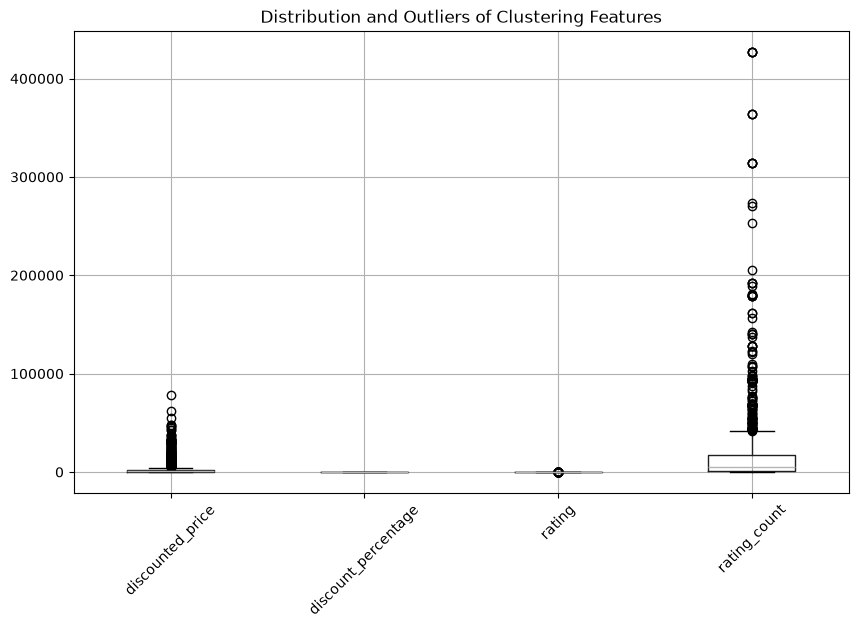

In [12]:
import matplotlib.pyplot as plt

df_cluster[features].boxplot(figsize=(10, 6))
plt.xticks(rotation=45)
plt.title('Distribution and Outliers of Clustering Features')
plt.show()

In [13]:
import numpy as np

df_cluster['log_price'] = np.log1p(df_cluster['discounted_price'])
df_cluster['log_rating_count'] = np.log1p(df_cluster['rating_count'])

In [14]:
cluster_features = [
    'log_price',
    'discount_percentage',
    'rating',
    'log_rating_count'
]
df_cluster[cluster_features].describe()

,log_price,discount_percentage,rating,log_rating_count
count,1462.000000,1462.000000,1462.000000,1462.000000
mean,6.861015,47.672367,4.096717,8.303800
std,1.426990,21.613905,0.289497,2.027792
min,3.688879,0.000000,2.000000,1.098612
25%,5.786897,32.000000,4.000000,7.083807
50%,6.684612,50.000000,4.100000,8.552560
75%,7.600902,63.000000,4.300000,9.760958
max,11.264349,94.000000,5.000000,12.964478


In [15]:
%pip install scikit-learn
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df_cluster[cluster_features])


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [16]:
X[:5]


array([[-0.60956801,  0.75568113,  0.35688975,  0.88461212],
       [-1.09547494, -0.21624808, -0.33420007,  1.17805367],
       [-1.09547494,  1.95902206, -0.67974499,  0.33273266],
       [-0.74442369,  0.24657536,  0.35688975,  1.55449498],
       [-1.27415836,  0.6168341 ,  0.35688975,  0.70624268]])

In [17]:
X.mean(axis=0), X.std(axis=0)

(array([ 2.62443965e-16, -1.36082056e-16,  2.05095099e-15, -1.55522350e-16]),
 array([1., 1., 1., 1.]))

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

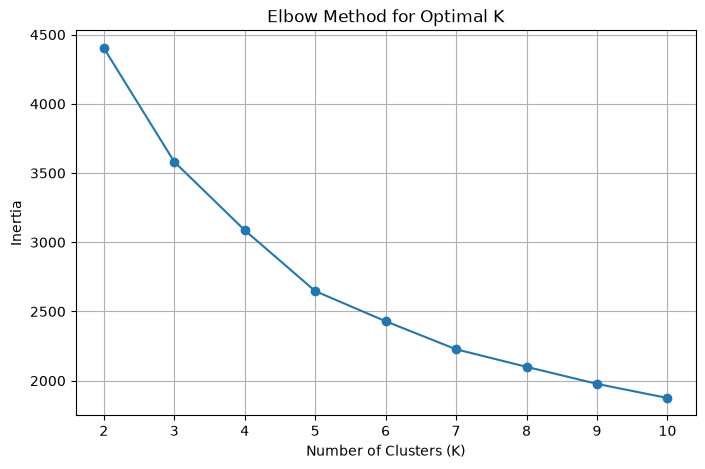

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_values)
plt.grid(True)

plt.show()

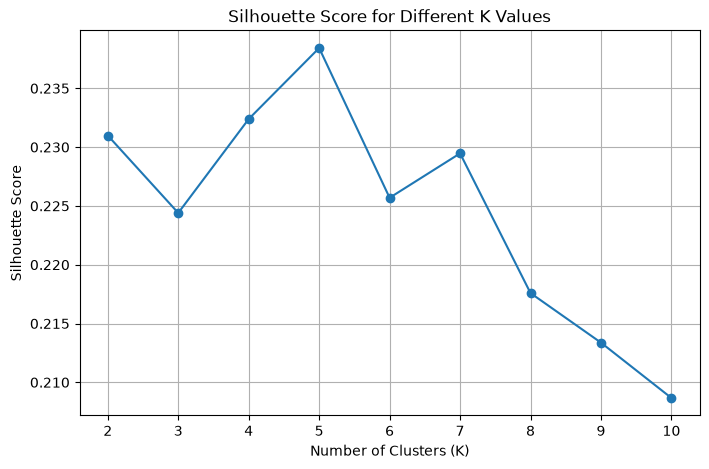

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [21]:
for k, inertia_value, silhouette in zip(
    k_values, inertia, silhouette_scores
):
    print(
        f"K={k}: Inertia={inertia_value:.2f}, "
        f"Silhouette Score={silhouette:.3f}"
    )

K=2: Inertia=4403.59, Silhouette Score=0.231
K=3: Inertia=3581.43, Silhouette Score=0.224
K=4: Inertia=3087.44, Silhouette Score=0.232
K=5: Inertia=2647.51, Silhouette Score=0.238
K=6: Inertia=2429.52, Silhouette Score=0.226
K=7: Inertia=2226.87, Silhouette Score=0.229
K=8: Inertia=2100.23, Silhouette Score=0.218
K=9: Inertia=1977.05, Silhouette Score=0.213
K=10: Inertia=1874.94, Silhouette Score=0.209


In [22]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df_cluster['cluster'] = kmeans.fit_predict(X)

In [23]:
df_cluster['cluster'].value_counts().sort_index()

cluster
0    188
1    298
2    418
3    277
4    281
Name: count, dtype: int64

In [24]:
cluster_summary = df_cluster.groupby('cluster')[
    ['discounted_price',
     'discount_percentage',
     'rating',
     'rating_count']
].mean().round(2)

cluster_summary

,discounted_price,discount_percentage,rating,rating_count
cluster,,,,
0,955.40,56.18,3.59,2156.63
1,755.46,61.52,4.20,1105.31
2,888.23,61.92,4.16,40662.39
3,12772.84,33.60,4.14,16445.28
4,932.15,19.98,4.20,15937.14


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


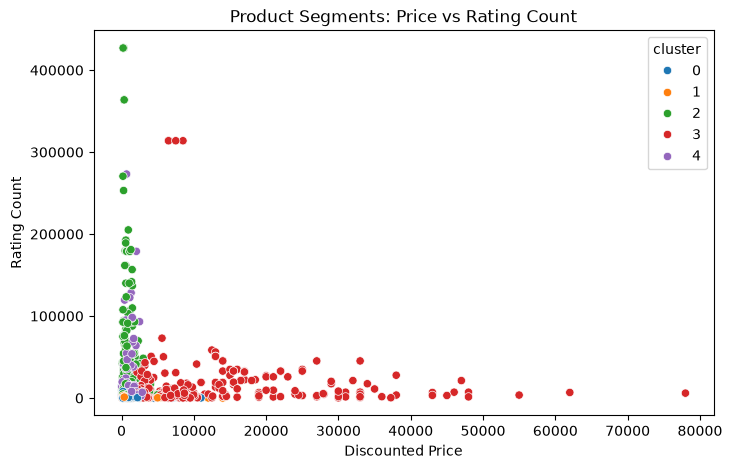

In [25]:
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_cluster,
    x='discounted_price',
    y='rating_count',
    hue='cluster',
    palette='tab10'
)

plt.title('Product Segments: Price vs Rating Count')
plt.xlabel('Discounted Price')
plt.ylabel('Rating Count')
plt.show()

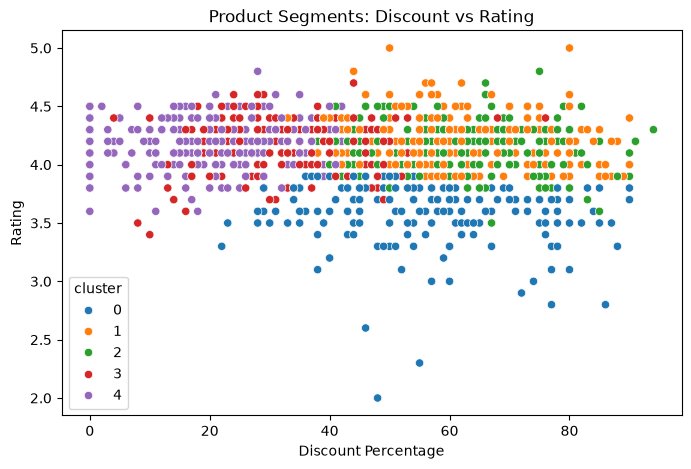

In [26]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_cluster,
    x='discount_percentage',
    y='rating',
    hue='cluster',
    palette='tab10'
)

plt.title('Product Segments: Discount vs Rating')
plt.xlabel('Discount Percentage')
plt.ylabel('Rating')
plt.show()

In [27]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

agg = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

agg_labels = agg.fit_predict(X)

In [28]:
agg_silhouette = silhouette_score(X, agg_labels)

print("K-Means Silhouette Score:", silhouette_scores[3])
print("Agglomerative Silhouette Score:", round(agg_silhouette, 3))

K-Means Silhouette Score: 0.2384273629840094
Agglomerative Silhouette Score: 0.189


In [29]:
pd.Series(agg_labels).value_counts().sort_index()

0    539
1    305
2    226
3    264
4    128
Name: count, dtype: int64

In [30]:
segment_profile = df_cluster.groupby('cluster')[
    ['discounted_price',
     'discount_percentage',
     'rating',
     'rating_count']
].agg(['mean', 'median']).round(2)

segment_profile

discounted_price         discount_percentage        rating         \
                    mean  median                mean median   mean median   
cluster                                                                     
0                 955.40   524.0               56.18   55.0   3.59   3.65   
1                 755.46   397.5               61.52   60.0   4.20   4.20   
2                 888.23   599.0               61.92   62.0   4.16   4.20   
3               12772.84  8799.0               33.60   32.0   4.14   4.10   
4                 932.15   765.0               19.98   21.0   4.20   4.20   

        rating_count           
                mean   median  
cluster                        
0            2156.63    582.0  
1            1105.31    835.0  
2           40662.39  19248.0  
3           16445.28   7109.0  
4           15937.14   7223.0

In [31]:
segment_size = (
    df_cluster['cluster']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

segment_size

cluster
0    12.86
1    20.38
2    28.59
3    18.95
4    19.22
Name: proportion, dtype: float64

In [32]:
segment_profile = (
    df_cluster.groupby('cluster')
    .agg(
        product_count=('product_name', 'count'),
        avg_price=('discounted_price', 'mean'),
        median_price=('discounted_price', 'median'),
        avg_discount=('discount_percentage', 'mean'),
        median_discount=('discount_percentage', 'median'),
        avg_rating=('rating', 'mean'),
        median_rating=('rating', 'median'),
        avg_rating_count=('rating_count', 'mean'),
        median_rating_count=('rating_count', 'median')
    )
    .round(2)
)

segment_profile

,product_count,avg_price,median_price,avg_discount,median_discount,avg_rating,median_rating,avg_rating_count,median_rating_count
cluster,,,,,,,,,
0,188,955.40,524.0,56.18,55.0,3.59,3.65,2156.63,582.0
1,298,755.46,397.5,61.52,60.0,4.20,4.20,1105.31,835.0
2,418,888.23,599.0,61.92,62.0,4.16,4.20,40662.39,19248.0
3,277,12772.84,8799.0,33.60,32.0,4.14,4.10,16445.28,7109.0
4,281,932.15,765.0,19.98,21.0,4.20,4.20,15937.14,7223.0


In [33]:
segment_profile['segment_percentage'] = (
    segment_profile['product_count']
    / len(df_cluster) * 100
).round(2)
segment_profile

,product_count,avg_price,median_price,avg_discount,median_discount,avg_rating,median_rating,avg_rating_count,median_rating_count,segment_percentage
cluster,,,,,,,,,,
0,188,955.40,524.0,56.18,55.0,3.59,3.65,2156.63,582.0,12.86
1,298,755.46,397.5,61.52,60.0,4.20,4.20,1105.31,835.0,20.38
2,418,888.23,599.0,61.92,62.0,4.16,4.20,40662.39,19248.0,28.59
3,277,12772.84,8799.0,33.60,32.0,4.14,4.10,16445.28,7109.0,18.95
4,281,932.15,765.0,19.98,21.0,4.20,4.20,15937.14,7223.0,19.22


In [34]:
segment_profile.to_csv(
    'product_segment_profile.csv',
    index=True
)